In [ ]:


if(!require(mgcv)) install.packages("mgcv", repos="https://cloud.r-project.org")
if(!require(readxl)) install.packages("readxl", repos="https://cloud.r-project.org")
library(mgcv)
library(readxl)
library(splines)


filepath_xlsx <- "/content/dataset_final.xlsx"
filepath_csv <- "/content/dataset_final.csv"

if (file.exists(filepath_csv)) {
  cat("Lendo arquivo CSV...\n")
  df <- read.csv(filepath_csv, check.names = FALSE)
} else if (file.exists(filepath_xlsx)) {
  cat("Lendo arquivo Excel e convertendo para DataFrame...\n")
  df <- as.data.frame(read_excel(filepath_xlsx))
} else {
  stop("Arquivo de dados não encontrado!")
}


cat("\n--- Primeiras linhas ---\n")
print(head(df))

cat("\n--- Valores únicos de ESCOLARIDADE ---\n")
print(unique(df$ESCOLARIDADE))



col_data <- grep("DATA.*OBITO|DATA.*ÓBITO", colnames(df), ignore.case = TRUE, value = TRUE)[1]
if(is.na(col_data)) col_data <- "DATA DE ÓBITO" # fallback

cat("\nColuna de data identificada como:", col_data, "\n")


dates_dmy <- as.Date(as.character(df[[col_data]]), format = "%d/%m/%Y")
dates_ymd <- as.Date(as.character(df[[col_data]]), format = "%Y-%m-%d")

final_dates <- dates_dmy
na_dmy <- sum(is.na(dates_dmy))
na_ymd <- sum(is.na(dates_ymd))

cat(sprintf("NAs usando %%d/%%m/%%Y: %d\n", na_dmy))
cat(sprintf("NAs usando %%Y-%%m-%%d: %d\n", na_ymd))


final_dates[is.na(final_dates)] <- dates_ymd[is.na(final_dates)]
na_sobrando <- sum(is.na(final_dates))
cat(sprintf("Total de NAs restantes na DATA DE ÓBITO após tentar ambos os formatos: %d\n", na_sobrando))

df$DATA_OBITO_CONV <- final_dates


Loading required package: mgcv

Loading required package: nlme

This is mgcv 1.9-4. For overview type '?mgcv'.

Loading required package: readxl



Lendo arquivo Excel e convertendo para DataFrame...

--- Primeiras linhas ---
   ANO DATA DE ÓBITO IDADE      SEXO   RAÇA    ESCOLARIDADE MUNICIPIO
1 2020    2020-12-05    24 Masculino  Parda 12 anos ou mais   Guarujá
2 2020    2020-12-05    24 Masculino  Parda 12 anos ou mais   Guarujá
3 2020    2020-12-05    24 Masculino  Parda 12 anos ou mais   Guarujá
4 2020    2020-12-05    24 Masculino  Parda 12 anos ou mais   Guarujá
5 2020    2020-03-04    19 Masculino Branca      4 a 7 anos    Santos
6 2020    2020-06-07    49  Feminino  Parda         Nenhuma   Guarujá
  LOCAL_MORTE                    OCUP
1    Hospital Auxiliar administrativo
2    Hospital     Auxiliar de compras
3    Hospital  Auxiliar de escritório
4    Hospital            Escriturário
5 Via pública            Motofretista
6    Hospital                    <NA>
                                                   CAUSA BASICA DA MORTE
1 Afogamento e submersão em águas naturais - outros locais especificados
2 Afogamento e subme

In [ ]:



# dia_ano: dia do ano (1 a 366)
df$dia_ano <- as.numeric(format(df$DATA_OBITO_CONV, "%j"))

# tempo: dias desde 2020-01-01
df$tempo <- as.numeric(df$DATA_OBITO_CONV - as.Date("2020-01-01"))

# anos_estudo: Nenhuma=0, 1 a 3 anos=2, 4 a 7 anos=5.5, 8 a 11 anos=9.5, 12 anos e mais=13

esc_clean <- trimws(tolower(as.character(df$ESCOLARIDADE)))

df$anos_estudo <- NA
df$anos_estudo[grepl("nenhuma", esc_clean)] <- 0
df$anos_estudo[grepl("1 a 3", esc_clean)] <- 2
df$anos_estudo[grepl("4 a 7", esc_clean)] <- 5.5
df$anos_estudo[grepl("8 a 11", esc_clean)] <- 9.5
df$anos_estudo[grepl("12 anos e mais|12 anos ou mais", esc_clean)] <- 13

# Fatores para SEXO, RACA, MUNICIPIO e LOCAL_MORTE
get_col_name <- function(pattern, cols) {
  res <- grep(pattern, cols, ignore.case = TRUE, value = TRUE)
  if(length(res) > 0) return(res[1]) else return(NULL)
}

col_sexo <- get_col_name("^SEXO$", colnames(df))
col_raca <- get_col_name("^RACA$|^RAÇA$", colnames(df))
col_municipio <- get_col_name("^MUNICIPIO$|^MUNICÍPIO$", colnames(df))
col_local_morte <- get_col_name("^LOCAL_MORTE$|^LOCAL.*MORTE$", colnames(df))
col_idade <- get_col_name("^IDADE$", colnames(df))

df$SEXO_f <- as.factor(df[[col_sexo]])
df$RACA_f <- as.factor(df[[col_raca]])
df$MUNICIPIO_f <- as.factor(df[[col_municipio]])
df$LOCAL_MORTE_f <- as.factor(df[[col_local_morte]])


linhas_iniciais <- nrow(df)

# Condição de remoção para IDADE, SEXO, RACA e ESCOLARIDADE
idade_valida <- !is.na(df[[col_idade]]) & df[[col_idade]] != "Ignorado" & df[[col_idade]] != ""
sexo_valido <- !is.na(df[[col_sexo]]) & df[[col_sexo]] != "Ignorado" & df[[col_sexo]] != ""
raca_valida <- !is.na(df[[col_raca]]) & df[[col_raca]] != "Ignorado" & df[[col_raca]] != ""
escolaridade_valida <- !is.na(df$anos_estudo) # os ignorados ou incompatíveis viraram NA aqui

data_valida <- !is.na(df$DATA_OBITO_CONV)

d_filtrado <- df[idade_valida & sexo_valido & raca_valida & escolaridade_valida & data_valida, ]

# Converter idade para numerico
d_filtrado$IDADE_num <- as.numeric(as.character(d_filtrado[[col_idade]]))
d_filtrado <- d_filtrado[!is.na(d_filtrado$IDADE_num), ]

linhas_removidas <- linhas_iniciais - nrow(d_filtrado)
cat(sprintf("Linhas iniciais: %d\n", linhas_iniciais))
cat(sprintf("Linhas restantes: %d\n", nrow(d_filtrado)))
cat(sprintf("Linhas removidas: %d\n", linhas_removidas))


Linhas iniciais: 474651
Linhas restantes: 458897
Linhas removidas: 15754


In [ ]:


set.seed(1)


if (nrow(d_filtrado) > 100000) {
  cat("Dataset muito grande (~458 mil linhas). Rodando validação cruzada em amostra de 100 mil linhas para maior agilidade.\n")
  idx_amostra <- sample(1:nrow(d_filtrado), 100000)
  d_cv <- d_filtrado[idx_amostra, ]
} else {
  d_cv <- d_filtrado
}

dobra <- sample(rep(1:5, length = nrow(d_cv)))

rmse_baseline <- numeric(5)
rmse_lm <- numeric(5)
rmse_bam <- numeric(5)

for(i in 1:5) {
  treino <- d_cv[dobra != i, ]
  teste  <- d_cv[dobra == i, ]

  # a) Linha de base (média do treino)
  pred_base <- mean(treino$IDADE_num)
  rmse_baseline[i] <- sqrt(mean((teste$IDADE_num - pred_base)^2))

  # b) lm
  m_lm <- lm(IDADE_num ~ tempo + dia_ano + anos_estudo + SEXO_f + RACA_f + MUNICIPIO_f + LOCAL_MORTE_f, data = treino)
  pred_lm <- predict(m_lm, newdata = teste)
  rmse_lm[i] <- sqrt(mean((teste$IDADE_num - pred_lm)^2, na.rm=TRUE))

  # c) bam (GAM rápido do mgcv)
  m_bam <- bam(IDADE_num ~ s(tempo) + s(dia_ano, bs = "cc") + s(anos_estudo, k = 4) +
                 SEXO_f + RACA_f + MUNICIPIO_f + LOCAL_MORTE_f, data = treino, discrete = TRUE)
  pred_bam <- predict(m_bam, newdata = teste)
  rmse_bam[i] <- sqrt(mean((teste$IDADE_num - pred_bam)^2, na.rm=TRUE))
}

cat(sprintf("RMSE Médio - Linha de Base: %.4f\n", mean(rmse_baseline)))
cat(sprintf("RMSE Médio - Regressão Linear (lm): %.4f\n", mean(rmse_lm)))
cat(sprintf("RMSE Médio - GAM (bam): %.4f\n", mean(rmse_bam)))


Dataset muito grande (~458 mil linhas). Rodando validação cruzada em amostra de 100 mil linhas para maior agilidade.
RMSE Médio - Linha de Base: 16.8554
RMSE Médio - Regressão Linear (lm): 14.7603
RMSE Médio - GAM (bam): 14.7129



Family: gaussian 
Link function: identity 

Formula:
IDADE_num ~ s(tempo) + s(dia_ano, bs = "cc") + s(anos_estudo, 
    k = 4) + SEXO_f + RACA_f + MUNICIPIO_f + LOCAL_MORTE_f

Parametric coefficients:
                                               Estimate Std. Error  t value
(Intercept)                                    72.48816    0.24981  290.169
SEXO_fMasculino                                -2.63014    0.04955  -53.076
RACA_fBranca                                   -5.43667    0.17683  -30.745
RACA_fIndígena                                 -4.75458    1.04095   -4.568
RACA_fParda                                   -13.91055    0.18093  -76.882
RACA_fPreta                                   -12.15210    0.19643  -61.864
MUNICIPIO_fCubatão                              6.37393    0.20747   30.722
MUNICIPIO_fGuarujá                              0.36313    0.18335    1.981
MUNICIPIO_fItanhaém                             8.85422    0.18162   48.751
MUNICIPIO_fMongaguá                   

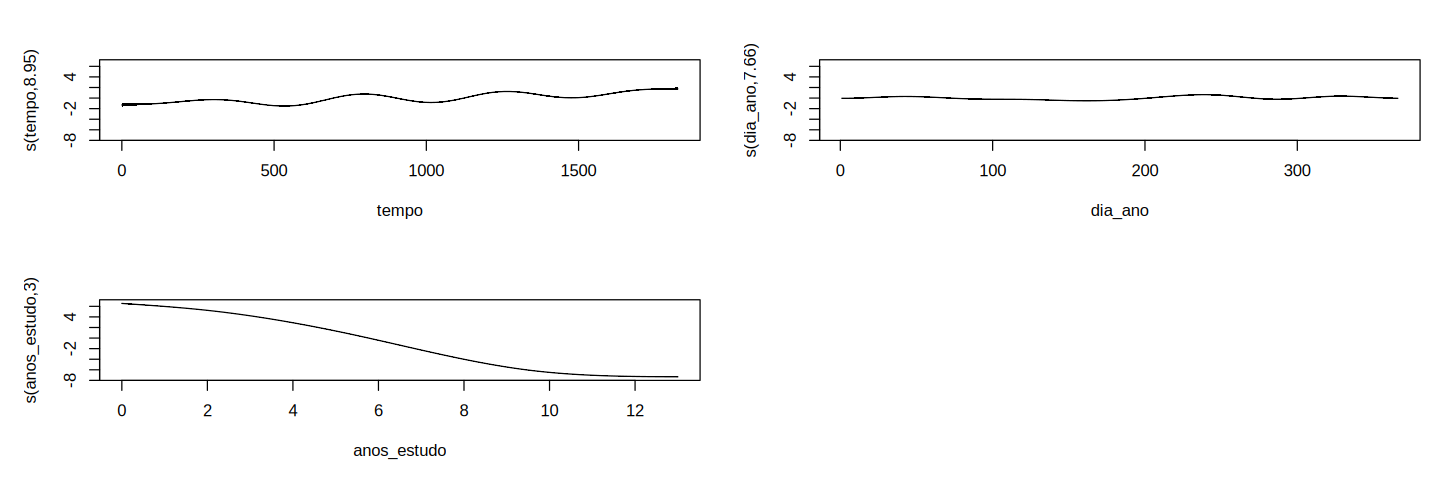

In [ ]:

# Passo 4 e 5: Ajuste do BAM final em todos os dados e Plotagem
g_final <- bam(IDADE_num ~ s(tempo) + s(dia_ano, bs = "cc") + s(anos_estudo, k = 4) +
                 SEXO_f + RACA_f + MUNICIPIO_f + LOCAL_MORTE_f, data = d_filtrado, discrete = TRUE)

print(summary(g_final))

# Plotando as 3 curvas suavizadas
options(repr.plot.width = 12, repr.plot.height = 4)
plot(g_final, pages = 1, shade = TRUE, scheme = 1)


### Análise dos Gráficos de Efeitos Suavizados (GAM)

Os três gráficos gerados representam os termos não lineares $s(\text{tempo})$, $s(\text{dia\_ano})$ e $s(\text{anos\_estudo})$. O eixo vertical ($y$) mostra a contribuição (positiva ou negativa) de cada variável para a **Idade ao Morrer** estimada, enquanto a linha tracejada ou área sombreada representa o intervalo de confiança.

---

#### 1. Tendência Temporal: `s(tempo)` (Primeiro Gráfico)
*   **O que o gráfico mostra**: Uma linha com oscilações suaves (ondas) que apresenta uma leve inclinação geral para cima ao longo do tempo (dias decorridos desde o início de 2020).
*   **Interpretação**:
    *   Existe uma oscilação cíclica de longo prazo na idade média de óbito.
    *   A tendência de subida ao longo do tempo indica que, de forma geral e muito sutil, a idade média ao morrer na amostra aumentou discretamente no decorrer dos anos analisados.

#### 2. Sazonalidade Anual: `s(dia_ano)` (Segundo Gráfico)
*   **O que o gráfico mostra**: Uma linha quase horizontal e muito próxima de zero durante todo o intervalo de 1 a 365 dias.
*   **Interpretação**:
    *   O efeito do dia do ano (sazonalidade) é estatisticamente significante devido ao tamanho massivo da amostra, mas seu efeito prático na variação da idade do óbito é **muito pequeno** (quase nulo).
    *   Diferentes estações do ano não exercem impacto visualmente expressivo na idade em que as pessoas morrem nesta base de dados.

#### 3. Impacto da Educação: `s(anos_estudo)` (Terceiro Gráfico)
*   **O que o gráfico mostra**: Uma curva descendente muito acentuada. O efeito começa positivo (acima de zero) para quem tem baixíssima ou nenhuma escolaridade (0 a 2 anos) e cai de forma íngreme para valores negativos à medida que os anos de estudo aumentam (chegando a -8 para 12+ anos).
*   **Interpretação**:
    *   **Efeito de Coorte (Geracional)**: Na prática, este gráfico não significa que estudar reduz a sua expectativa de vida. O que ele reflete é uma realidade demográfica histórica brasileira: as pessoas mais idosas que estão falecendo hoje (com idades muito avançadas, de 80 ou 90 anos) nasceram na primeira metade do século XX, época em que o acesso à escola era extremamente restrito. Logo, a imensa maioria dos óbitos em idades muito avançadas se concentra na faixa de baixa escolaridade.
    *   Por outro lado, indivíduos mais jovens que vêm a óbito (por exemplo, por causas externas ou doenças precoces) nasceram em gerações recentes que tiveram muito mais acesso ao ensino formal, concentrando-se nas faixas de escolaridade mais altas.